In [19]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pydeseq2.dds import DeseqDataSet



## Checks


In [2]:
counts_df = pd.read_csv("../data/processed/raw_merged.csv", index_col=0)
metadata = pd.read_csv("../data/processed/metadata_merged.csv", index_col=0)

# Asegurar que coinciden los pacientes
metadata = metadata.loc[counts_df.index]

print(counts_df.shape)
# (200, 60000)

print(metadata.head())

(232, 59427)
                Condition
TCGA-BH-A18V-11   Healthy
TCGA-BH-A0BM-11   Healthy
TCGA-BH-A1F2-11   Healthy
TCGA-BH-A1F8-11   Healthy
TCGA-BH-A18S-11   Healthy


In [4]:
assert counts_df.index.equals(metadata.index)
assert (counts_df.values >= 0).all()
assert (counts_df.values % 1 == 0).all()

print(metadata["Condition"].value_counts())

Condition
Cancer     119
Healthy    113
Name: count, dtype: int64


In [6]:
# ¿Tienen los mismos identificadores?
print("Mismo número de pacientes:",
      len(counts_df.index) == len(metadata.index))

print("Mismos pacientes:",
      set(counts_df.index) == set(metadata.index))

print("Mismo orden:",
      counts_df.index.equals(metadata.index))

# Duplicados
print("Duplicados en counts:", counts_df.index.duplicated().sum())
print("Duplicados en metadata:", metadata.index.duplicated().sum())

Mismo número de pacientes: True
Mismos pacientes: True
Mismo orden: True
Duplicados en counts: 0
Duplicados en metadata: 0


## QC on Raw counts

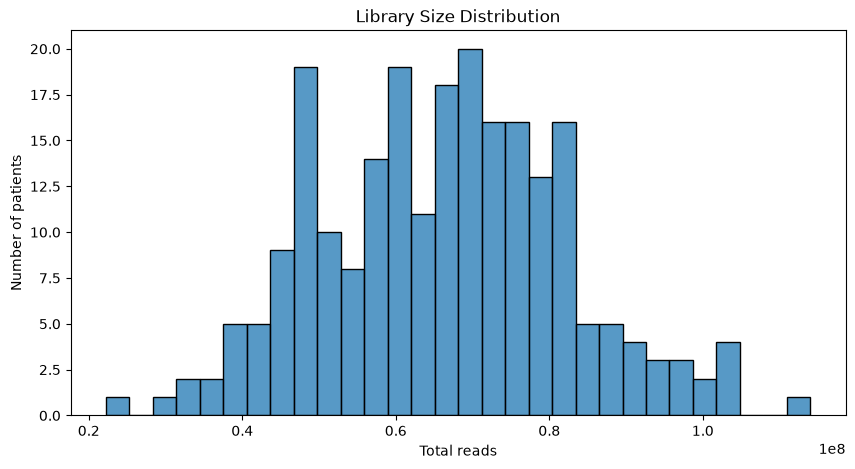

In [ ]:
# Library size
# To detect differencies in sequencing depth between samples, we can calculate the library size for each sample by summing the counts across all genes. This will give us an idea of the total number of reads for each patient.

library_sizes = counts_df.sum(axis=1)

plt.figure(figsize=(10, 5))
sns.histplot(library_sizes, bins=30)

plt.xlabel("Total reads")
plt.ylabel("Number of patients")
plt.title("Library Size Distribution")
plt.show()

In [ ]:
# Detecting zero counts

zero_percentage = (
    (counts_df == 0).sum().sum()
    / counts_df.size
) * 100

print(f"Zero percentage: {zero_percentage:.2f}%")

Zero percentage: 42.16%


In [13]:
zero_genes = (counts_df.sum(axis=0) == 0).sum()

print("Genes without expression:", zero_genes)

Genes without expression: 2868


In [14]:
# Identify genes with at least one count > 0
genes_to_keep = counts_df.columns[
    counts_df.sum(axis=0) > 0
]

# Filter the DataFrame
counts_filtered = counts_df[genes_to_keep].copy()

print("Genes originales:", counts_df.shape[1])
print("Genes eliminados:", counts_df.shape[1] - counts_filtered.shape[1])
print("Genes restantes:", counts_filtered.shape[1])

Genes originales: 59427
Genes eliminados: 2868
Genes restantes: 56559


In [16]:
# Comprobar que no quedan genes completamente vacíos
remaining_zero_genes = (
    counts_filtered.sum(axis=0) == 0
).sum()

print("Genes sin expresión restantes:", remaining_zero_genes)

# Comprobar dimensiones
print("Nueva matriz:", counts_filtered.shape)

# Comprobar que no hemos perdido pacientes
print("Pacientes:", counts_filtered.shape[0])

Genes sin expresión restantes: 0
Nueva matriz: (232, 56559)
Pacientes: 232


Filter low expression genes


In [17]:
# Parameters
min_counts = 10
min_samples = int(0.10 * len(counts_filtered))

# Filter genes
genes_to_keep = (
    (counts_filtered >= min_counts).sum(axis=0) >= min_samples
)

counts_filtered_2 = counts_filtered.loc[:, genes_to_keep].copy()

print("Genes antes:", counts_filtered.shape[1])
print("Genes después:", counts_filtered_2.shape[1])
print("Genes eliminados:", (~genes_to_keep).sum())

Genes antes: 56559
Genes después: 27249
Genes eliminados: 29310


In [18]:
print("Shape:", counts_filtered_2.shape)

# Distribución de genes conservados
print(
    (counts_filtered_2 >= 10).sum(axis=0).describe()
)

Shape: (232, 27249)
count    27249.000000
mean       184.600939
std         70.524435
min         23.000000
25%        143.000000
50%        231.000000
75%        232.000000
max        232.000000
dtype: float64


## VST (Variance Stabilizing Transformation)

Es una transformación utilizada en análisis de RNA-seq, implementada en DESeq2.

El problema de los raw counts es que su varianza depende de su media.

VST busca estabilizar esa relación entre media y varianza.

VST no es simplemente aplicar un logaritmo. Utiliza el modelo de dispersión estimado por DESeq2 para transformar los datos

Primero, creamos un objeto DeseqDataSet con un diseño ~1, es decir, sin introducir la variable condition en el modelo.

In [20]:


# Metadata sin etiquetas de diagnóstico
metadata_eda = pd.DataFrame(
    index=counts_filtered_2.index
)

# Crear dataset
dds_eda = DeseqDataSet(
    counts=counts_filtered_2.astype(int),
    metadata=metadata_eda,
    design="~1",
    n_cpus=4
)

# Aplicar VST
dds_eda.vst(use_design=False)

# Extraer matriz transformada
vst_counts = dds_eda.layers["vst_counts"]

vst_df = pd.DataFrame(
    vst_counts,
    index=counts_filtered_2.index,
    columns=counts_filtered_2.columns
)

print("Original:", counts_filtered_2.shape)
print("VST:", vst_df.shape)

Fit type used for VST : parametric
Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.42 seconds.

Fitting dispersions...
... done in 17.11 seconds.



Original: (232, 27249)
VST: (232, 27249)


In [21]:
print("Shape:", vst_df.shape)

print("NaN:", vst_df.isna().sum().sum())

print("Inf:", np.isinf(vst_df.values).sum())

print("\nEstadísticas:")
print(vst_df.describe().loc[["min", "mean", "50%", "max"]])

Shape: (232, 27249)
NaN: 0
Inf: 0

Estadísticas:
          A1BG  A1BG-AS1      A1CF        A2M   A2M-AS1      A2ML1     A2MP1  \
min   2.055360  3.391531  2.055360  13.639755  4.869984   3.267435  2.721840   
mean  4.420924  6.547140  3.265299  15.956185  7.098974   6.166651  5.010236   
50%   4.468220  6.671294  3.198230  16.091532  7.048893   5.717989  5.008165   
max   6.324594  8.222186  9.649705  18.416402  9.165118  13.533641  7.825215   

         A4GALT     A4GNT       AAAS  ...     ZWILCH      ZWINT       ZXDA  \
min    7.481340  2.055360   9.565324  ...   7.974546   6.781743   6.988211   
mean  10.038193  3.531204  11.205919  ...   9.684593   9.918675   8.772684   
50%   10.042545  3.589973  11.213379  ...   9.527560   9.900070   8.840774   
max   12.582383  6.768519  12.188212  ...  11.933708  14.482731  10.402469   

           ZXDB       ZXDC     ZYG11A     ZYG11B        ZYX      ZZEF1  \
min    9.334342  10.230052   3.102851  10.431792  10.005941  11.082262   
mean  10.52

Vamos a visualizar la distribución de expresión antes y después de transformar.

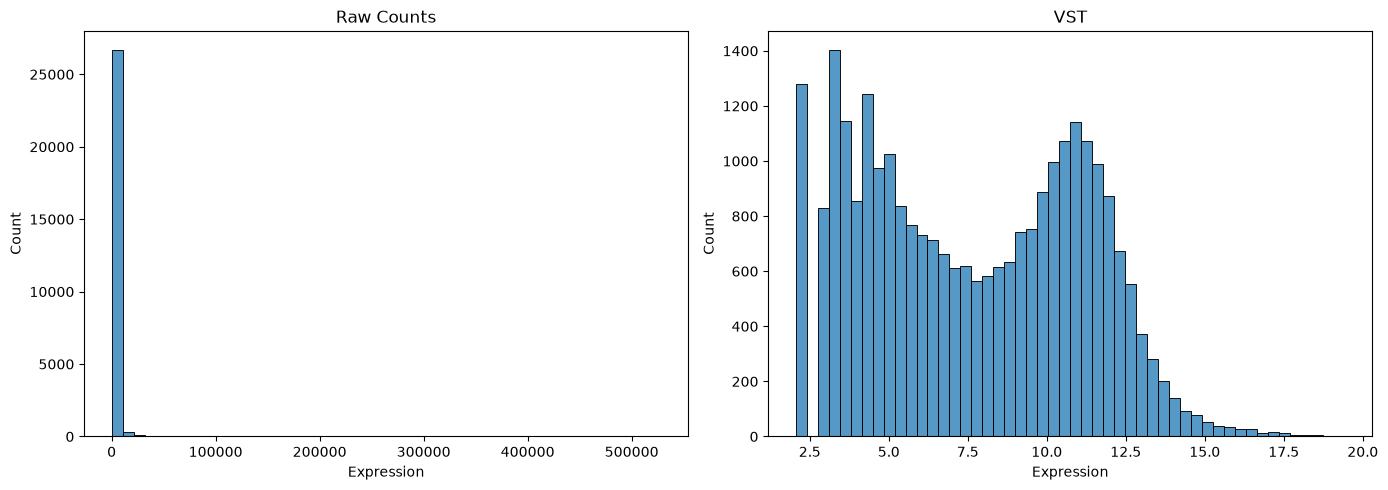

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw counts
sns.histplot(
    counts_filtered_2.iloc[0],
    bins=50,
    ax=axes[0]
)
axes[0].set_title("Raw Counts")
axes[0].set_xlabel("Expression")

# VST
sns.histplot(
    vst_df.iloc[0],
    bins=50,
    ax=axes[1]
)
axes[1].set_title("VST")
axes[1].set_xlabel("Expression")

plt.tight_layout()
plt.show()

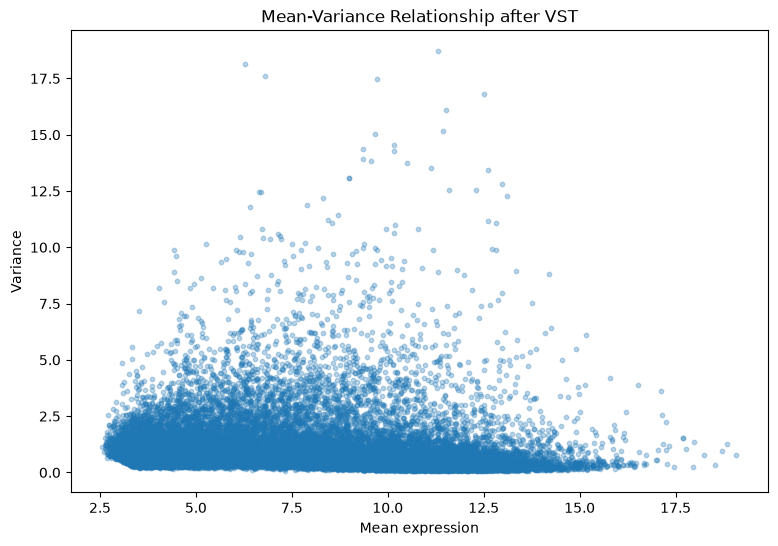

In [23]:
# Media y varianza por gen

gene_means = vst_df.mean(axis=0)
gene_variances = vst_df.var(axis=0)

plt.figure(figsize=(9, 6))

plt.scatter(
    gene_means,
    gene_variances,
    alpha=0.3,
    s=10
)

plt.xlabel("Mean expression")
plt.ylabel("Variance")
plt.title("Mean-Variance Relationship after VST")

plt.show()

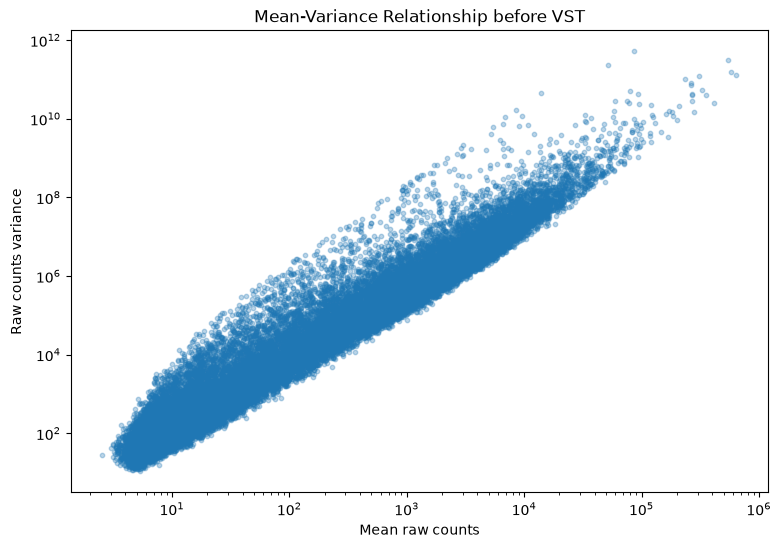

In [24]:
raw_means = counts_filtered_2.mean(axis=0)
raw_variances = counts_filtered_2.var(axis=0)

plt.figure(figsize=(9, 6))

plt.scatter(
    raw_means,
    raw_variances,
    alpha=0.3,
    s=10
)

plt.xlabel("Mean raw counts")
plt.ylabel("Raw counts variance")
plt.title("Mean-Variance Relationship before VST")

plt.xscale("log")
plt.yscale("log")

plt.show()